# TP5 · Ej. 2 — Propuesta C: VAE sobre **fórmulas matemáticas y de física** (IM2LATEX-100K)
*(Propuesta alternativa; el `ejercicio2.ipynb` original no se modifica.)*

**Dataset (GitHub / sitio del proyecto):** [harvardnlp/im2markup](https://github.com/harvardnlp/im2markup) — **IM2LATEX-100K** (Deng et al., ICML 2017, licencia CC0): ~100 000 imágenes de fórmulas reales extraídas de papers de arXiv (física teórica, matemática, mecánica cuántica…), con su código LaTeX. Se usa la versión procesada (imágenes recortadas y paddeadas, 617 MB) y las listas de fórmulas normalizadas.

**Idea (siguiendo lo visto en clase sobre VAE):** el AE común no impone estructura al espacio latente; el VAE sí, y eso permite *moverse entre conceptos y crear puntos nuevos que tengan sentido*. Acá los "conceptos" son **estructuras de fórmulas** (fracciones, sumatorias, integrales, raíces, sub/superíndices, matrices…). Se comprueba:
1. Si las muestras del prior *se parecen* a fórmulas reales (distancia de Fréchet en el espacio de un juez que reconoce estructura).
2. Si el latente se organiza por **complejidad/estructura**: sondeo lineal del largo del LaTeX y de la presencia de `\frac`, `\int`, `\sum`…; interpolación entre dos fórmulas reales.
3. AE (β=0) vs VAE (β>0).

> Colab: GPU T4 recomendada (~10–15 min con 40 000 imágenes). `RAPIDO=True` hace una prueba de humo.

In [1]:
RAPIDO = False
SEED   = 0
N_MAX  = 40_000 if not RAPIDO else 3_000     # cantidad de fórmulas a usar (el dataset procesado tiene ~94 000)
ALTO, ANCHO = 64, 320                         # solo fórmulas de 1 renglón (alto 64) y ancho <= 320 (la mayoría)
D_LAT  = 64
EPOCAS = 20 if not RAPIDO else 3
BETAS  = [0.0, 1.0, 4.0]
import os, io, tarfile, urllib.request, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from scipy import linalg
np.random.seed(SEED); torch.manual_seed(SEED)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'; print('dispositivo:', dev)

dispositivo: cuda


In [2]:
# ---- Descarga (617 MB + listas) -------------------------------------------------------------------
BASE = 'https://im2markup.yuntiandeng.com/data/'
for f in ['formula_images_processed.tar.gz', 'im2latex_formulas.norm.lst', 'im2latex_train_filter.lst', 'im2latex_test_filter.lst']:
    if not os.path.exists(f): print('descargando', f); urllib.request.urlretrieve(BASE + f, f)
# fórmulas normalizadas (índice de línea = índice de fórmula, base 0; NO borrar líneas vacías)
formulas = open('im2latex_formulas.norm.lst', encoding='utf-8', newline='\n').read().split('\n')
listas = pd.concat([pd.read_csv(f, sep=' ', header=None, names=['img','idx']) for f in ('im2latex_train_filter.lst','im2latex_test_filter.lst')])
f2idx = dict(zip(listas.img, listas.idx)); print('imágenes con fórmula:', len(f2idx), '| fórmulas:', len(formulas))

descargando formula_images_processed.tar.gz
descargando im2latex_formulas.norm.lst
descargando im2latex_train_filter.lst
descargando im2latex_test_filter.lst
imágenes con fórmula: 85613 | fórmulas: 103560


imágenes: (36201, 1, 64, 320) | MB: 741.39648


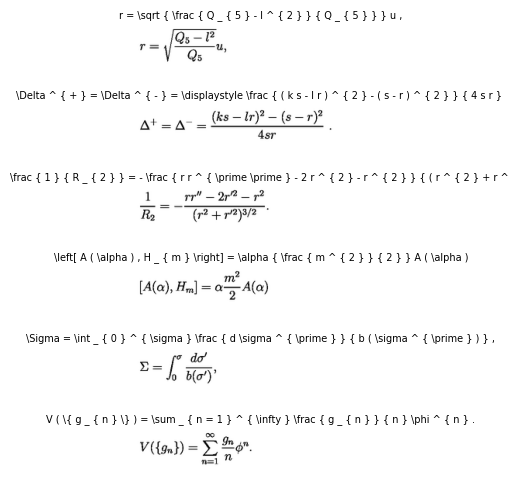

In [3]:
# ---- Lectura en streaming del .tar.gz: solo 1 renglón (alto 64) y ancho <= 320; se pega a la izquierda en 64x320 --
imgs, tex = [], []
with tarfile.open('formula_images_processed.tar.gz') as t:
    for m in t:
        if not m.isfile(): continue
        nombre = os.path.basename(m.name)
        if nombre not in f2idx: continue
        im = Image.open(io.BytesIO(t.extractfile(m).read())).convert('L')
        if im.size[1] != ALTO or im.size[0] > ANCHO: continue
        a = 255 - np.asarray(im, dtype=np.uint8)                       # tinta alta
        lienzo = np.zeros((ALTO, ANCHO), np.uint8); lienzo[:, :a.shape[1]] = a
        imgs.append(lienzo); tex.append(formulas[f2idx[nombre]])
        if len(imgs) >= N_MAX: break
X = np.stack(imgs)[:, None]; print('imágenes:', X.shape, '| MB:', X.nbytes/1e6)
fig, ax = plt.subplots(6, 1, figsize=(12, 5))
for a, i in zip(ax, range(6)): a.imshow(X[i,0], cmap='gray_r'); a.axis('off'); a.set_title(tex[i][:110], fontsize=7)
plt.tight_layout(); plt.show()

## 1. "Conceptos" de una fórmula
Etiquetas derivadas del LaTeX: presencia de estructuras (`\frac`, `\sum`, `\int`, `\sqrt`, superíndice `^`, subíndice `_`, `\left`, letras griegas) y **largo en tokens** (complejidad).

In [4]:
ESTR = {'frac': r'\frac', 'suma': r'\sum', 'integral': r'\int', 'raiz': r'\sqrt', 'sup': '^', 'sub': '_', 'left': r'\left', 'griega': 'GREEK'}
import re
GR = re.escape(chr(92)) + '(alpha|beta|gamma|delta|epsilon|theta|lambda|mu|nu|pi|rho|sigma|phi|psi|omega|Phi|Psi|Omega|Delta|Gamma)(?![A-Za-z])'
Yb = np.stack([[bool(re.search(GR if k=='griega' else re.escape(p), s)) for k, p in ESTR.items()] for s in tex]).astype(np.float32)
largo = np.array([len(s.split()) for s in tex], np.float32)
print(pd.DataFrame({'fracción con la estructura': Yb.mean(0)}, index=ESTR.keys()).round(3)); print('largo en tokens: media', largo.mean().round(1), 'máx', largo.max())

          fracción con la estructura
frac                           0.729
suma                           0.128
integral                       0.159
raiz                           0.114
sup                            0.803
sub                            0.795
left                           0.270
griega                         0.722
largo en tokens: media 50.9 máx 399.0


In [5]:
rng = np.random.default_rng(SEED); idx = rng.permutation(len(X)); ntr = int(.9*len(X)); tr, te = idx[:ntr], idx[ntr:]
Xu = torch.tensor(X)                                   # uint8; se convierte a float por lote
Yt = torch.tensor(Yb); Lt = torch.tensor(largo)
def lote(ix): return Xu[ix].float().div(255).to(dev)

class Juez(nn.Module):
    def __init__(s):
        super().__init__()
        s.f = nn.Sequential(nn.Conv2d(1,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                            nn.Conv2d(64,128,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d((2,8)),nn.Flatten(),nn.Linear(2048,128),nn.ReLU())
        s.o = nn.Linear(128, Yb.shape[1] + 1)             # 8 estructuras + largo
    def forward(s, x): return s.o(s.f(x))
juez = Juez().to(dev); opt = torch.optim.Adam(juez.parameters(), 1e-3)
for e in range(3 if RAPIDO else 6):
    perm = torch.tensor(tr)[torch.randperm(len(tr))]
    for i in range(0, len(perm), 128):
        b = perm[i:i+128]; out = juez(lote(b))
        l = F.binary_cross_entropy_with_logits(out[:, :-1], Yt[b].to(dev)) + F.mse_loss(out[:, -1], (Lt[b]/50).to(dev))
        opt.zero_grad(); l.backward(); opt.step()
juez.eval()
with torch.no_grad():
    o = torch.cat([juez(lote(torch.tensor(te[i:i+256]))).cpu() for i in range(0,len(te),256)])
acc = ((o[:, :-1] > 0).float() == Yt[te]).float().mean(0); print('exactitud del juez por estructura:', dict(zip(ESTR, acc.numpy().round(3))))

exactitud del juez por estructura: {'frac': np.float32(0.915), 'suma': np.float32(0.926), 'integral': np.float32(0.959), 'raiz': np.float32(0.904), 'sup': np.float32(0.803), 'sub': np.float32(0.801), 'left': np.float32(0.883), 'griega': np.float32(0.727)}


## 2. VAE convolucional (64×320)
Codificador conv (4 etapas stride 2) → (μ, log σ²) ∈ ℝ^d; decodificador simétrico; pérdida BCE + β·KL. β=0 es un autoencoder común: reconstruye pero no estructura el latente (lo visto en clase).

In [6]:
class VAE(nn.Module):
    def __init__(s, d=D_LAT):
        super().__init__()
        s.enc = nn.Sequential(nn.Conv2d(1,32,4,2,1),nn.ReLU(),nn.Conv2d(32,64,4,2,1),nn.ReLU(),nn.Conv2d(64,128,4,2,1),nn.ReLU(),nn.Conv2d(128,128,4,2,1),nn.ReLU(),nn.Flatten())  # 128x4x20
        s.mu, s.lv = nn.Linear(10240,d), nn.Linear(10240,d); s.fc = nn.Linear(d,10240)
        s.dec = nn.Sequential(nn.ConvTranspose2d(128,128,4,2,1),nn.ReLU(),nn.ConvTranspose2d(128,64,4,2,1),nn.ReLU(),nn.ConvTranspose2d(64,32,4,2,1),nn.ReLU(),nn.ConvTranspose2d(32,1,4,2,1))
    def encode(s, x): h = s.enc(x); return s.mu(h), s.lv(h)
    def decode(s, z): return s.dec(F.relu(s.fc(z)).view(-1,128,4,20))
    def forward(s, x):
        mu, lv = s.encode(x); z = mu + torch.randn_like(mu)*torch.exp(.5*lv); return s.decode(z), mu, lv
def entrenar(beta, ep=EPOCAS, bs=128):
    torch.manual_seed(SEED); m = VAE().to(dev); o = torch.optim.Adam(m.parameters(), 1e-3); trt = torch.tensor(tr)
    for e in range(ep):
        perm = trt[torch.randperm(len(trt))]; tot = 0
        for i in range(0, len(perm), bs):
            xb = lote(perm[i:i+bs]); lg, mu, lv = m(xb)
            rec = F.binary_cross_entropy_with_logits(lg, xb, reduction='sum')/len(xb); kl = (-.5*(1+lv-mu**2-lv.exp()).sum(1)).mean()
            l = rec + beta*kl; o.zero_grad(); l.backward(); o.step(); tot += l.item()*len(xb)
        if e % max(1,ep//4)==0 or e==ep-1: print(f'  β={beta} época {e+1}/{ep} pérdida {tot/len(trt):.1f}')
    return m.eval()
modelos = {b: entrenar(b) for b in BETAS}

  β=0.0 época 1/20 pérdida 5631.2
  β=0.0 época 6/20 pérdida 1928.0
  β=0.0 época 11/20 pérdida 1770.9
  β=0.0 época 16/20 pérdida 1668.0
  β=0.0 época 20/20 pérdida 1621.9
  β=1.0 época 1/20 pérdida 2624.6
  β=1.0 época 6/20 pérdida 1797.9
  β=1.0 época 11/20 pérdida 1701.1
  β=1.0 época 16/20 pérdida 1642.3
  β=1.0 época 20/20 pérdida 1610.8
  β=4.0 época 1/20 pérdida 2832.6
  β=4.0 época 6/20 pérdida 2003.0
  β=4.0 época 11/20 pérdida 1934.5
  β=4.0 época 16/20 pérdida 1889.2
  β=4.0 época 20/20 pérdida 1861.3


## 3. ¿Las muestras "pertenecen" al conjunto? (Fréchet en el espacio del juez) y ¿hay estructura en el latente?

In [7]:
@torch.no_grad()
def feats_x(Xf): return torch.cat([juez.f(Xf[i:i+256].to(dev)).cpu() for i in range(0,len(Xf),256)]).numpy().astype(np.float64)
def frechet(a,b):
    m1,m2=a.mean(0),b.mean(0); s1,s2=np.cov(a,rowvar=False),np.cov(b,rowvar=False); c=linalg.sqrtm(s1@s2); c=c.real if np.iscomplexobj(c) else c
    return float(((m1-m2)**2).sum()+np.trace(s1+s2-2*c))
Fte = feats_x(torch.cat([lote(torch.tensor(te[i:i+512])).cpu() for i in range(0,len(te),512)])); piso = frechet(Fte[:len(Fte)//2], Fte[len(Fte)//2:]); print(f'piso real↔real: {piso:.2f}')
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
filas = []; muestras = {}
for b, m in modelos.items():
    with torch.no_grad():
        S = torch.sigmoid(m.decode(torch.randn(1500, D_LAT, device=dev))).cpu(); muestras[b] = S
        MU = torch.cat([m.encode(lote(torch.tensor(te[i:i+256])))[0].cpu() for i in range(0,len(te),256)]).numpy()
    r2 = []
    for tgt in (largo[te], Yb[te][:,0], Yb[te][:,2]):                  # largo, \frac, \int
        a,b_,c_,d_ = train_test_split(MU, tgt, random_state=0); r2.append(Ridge(1e-2).fit(a,c_).score(b_,d_))
    filas.append((b, round(frechet(feats_x(S), Fte),2), *np.round(r2,3)))
print(pd.DataFrame(filas, columns=['β','Fréchet(prior→real)','R² latente→largo','R² latente→\\frac','R² latente→\\int']).to_string(index=False))

/tmp/ipykernel_2107/1480238443.py:4: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  m1,m2=a.mean(0),b.mean(0); s1,s2=np.cov(a,rowvar=False),np.cov(b,rowvar=False); c=linalg.sqrtm(s1@s2); c=c.real if np.iscomplexobj(c) else c


piso real↔real: 0.25


/tmp/ipykernel_2107/1480238443.py:4: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  m1,m2=a.mean(0),b.mean(0); s1,s2=np.cov(a,rowvar=False),np.cov(b,rowvar=False); c=linalg.sqrtm(s1@s2); c=c.real if np.iscomplexobj(c) else c
/tmp/ipykernel_2107/1480238443.py:4: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  m1,m2=a.mean(0),b.mean(0); s1,s2=np.cov(a,rowvar=False),np.cov(b,rowvar=False); c=linalg.sqrtm(s1@s2); c=c.real if np.iscomplexobj(c) else c


  β  Fréchet(prior→real)  R² latente→largo  R² latente→\frac  R² latente→\int
0.0                92.08             0.608             0.395            0.147
1.0                70.99             0.608             0.351            0.163
4.0                78.90             0.613             0.342            0.176


/tmp/ipykernel_2107/1480238443.py:4: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  m1,m2=a.mean(0),b.mean(0); s1,s2=np.cov(a,rowvar=False),np.cov(b,rowvar=False); c=linalg.sqrtm(s1@s2); c=c.real if np.iscomplexobj(c) else c


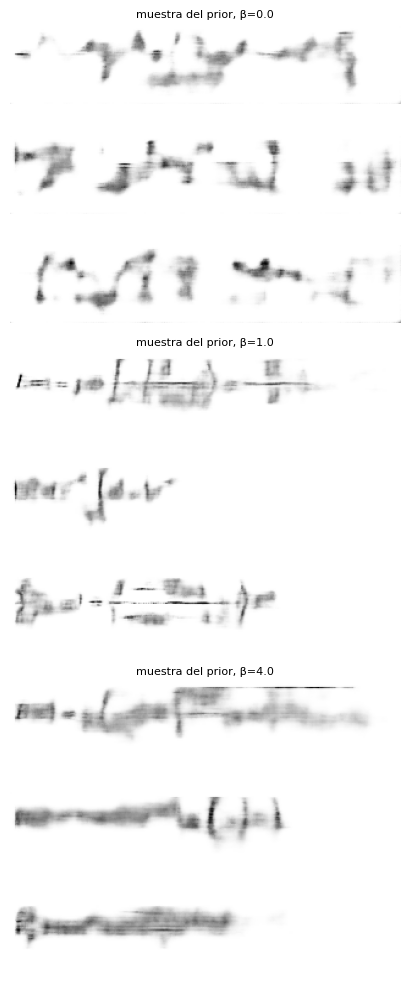

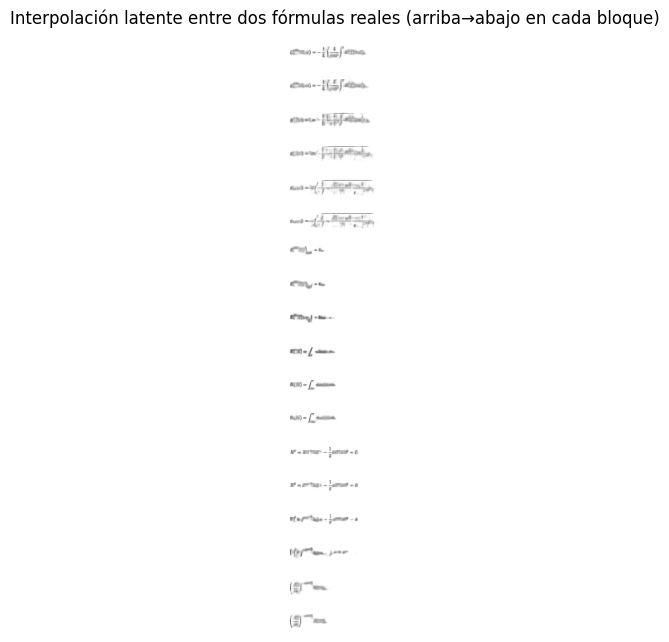

In [8]:
fig, ax = plt.subplots(len(BETAS)*3, 1, figsize=(12, 1.0*len(BETAS)*3+1))
for r, b in enumerate(BETAS):
    for k in range(3): ax[r*3+k].imshow(muestras[b][k,0], cmap='gray_r'); ax[r*3+k].axis('off'); ax[r*3+k].set_title(f'muestra del prior, β={b}' if k==0 else '', fontsize=8)
plt.tight_layout(); plt.show()
# interpolación entre dos fórmulas reales (β=1)
m = modelos[1.0] if 1.0 in modelos else modelos[BETAS[0]]
pares = rng.choice(len(te), (3,2))
fig, ax = plt.subplots(3*6, 1, figsize=(12, 6.5))
for r,(i,j) in enumerate(pares):
    with torch.no_grad():
        a, b_ = m.encode(lote(torch.tensor(te[[i,j]])))[0]; Z = torch.stack([a*(1-t)+b_*t for t in np.linspace(0,1,6)]); S = torch.sigmoid(m.decode(Z)).cpu()
    for k in range(6): ax[r*6+k].imshow(S[k,0], cmap='gray_r'); ax[r*6+k].axis('off')
plt.suptitle('Interpolación latente entre dos fórmulas reales (arriba→abajo en cada bloque)'); plt.tight_layout(); plt.show()

## 4. Guía de conclusiones
* ¿El AE (β=0) tiene R² latente→estructura menor o mayor que el VAE? ¿Y su FD (muestras del prior)? Debería verse el efecto visto en clase: sin KL el prior N(0,I) no cae donde el AE aprendió.
* Las muestras son **imágenes de fórmulas "tipo fórmula"** (trazos, renglones, índices), no LaTeX válido: para generar LaTeX habría que pasar a un modelo de secuencias (VAE con decodificador recurrente) — extensión posible.
* Citas: Deng, Kanervisto, Ling & Rush (2017), *Image-to-Markup Generation with Coarse-to-Fine Attention*, ICML; Kingma & Welling (2014); Higgins et al. (2017); Heusel et al. (2017).